In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

In [2]:
CADU_DIR = Path("cadus")
ASM_LEN = 4
CADU_LEN = 1279  # 4 byte ASM + 1275 byte RS(255,223) codeblock (interleave 5)
FRAME_LEN = 1115  # transfer frame length, excluding the 160 bytes of Reed-Solomon parity
HEADER_LEN = 6
OCF_LEN = 4
IDLE_APID = 0x7FF
NO_PACKET_START = 0x7FF  # first header pointer: frame holds only packet continuation data
TOP_N = 15

In [3]:
def iter_packets(path: Path):
    """Reassemble the source packets of one dump (per virtual channel); yields (vcid, packet bytes)."""
    buffers: dict[int, bytearray] = {}
    last_count: dict[int, int] = {}
    synced: dict[int, bool] = {}

    data = path.read_bytes()
    for start in range(0, len(data) - CADU_LEN + 1, CADU_LEN):
        frame = data[start + ASM_LEN : start + ASM_LEN + FRAME_LEN]
        vcid = (frame[1] >> 1) & 0x7
        vc_count = frame[3]
        first_header_ptr = int.from_bytes(frame[4:6]) & 0x7FF
        has_ocf = frame[1] & 1
        payload = frame[HEADER_LEN : FRAME_LEN - OCF_LEN * has_ocf]

        buf = buffers.setdefault(vcid, bytearray())
        if vcid in last_count and vc_count != (last_count[vcid] + 1) & 0xFF:
            buf.clear()  # lost frames: whatever was half-assembled is garbage
            synced[vcid] = False
        last_count[vcid] = vc_count

        if not synced.get(vcid):
            if first_header_ptr >= len(payload):
                continue  # still waiting for a frame in which a packet starts
            payload = payload[first_header_ptr:]
            synced[vcid] = True
        buf += payload

        while len(buf) >= HEADER_LEN:
            if buf[0] >> 5:  # packet version number must be 0, otherwise we've lost sync
                buf.clear()
                synced[vcid] = False
                break
            length = int.from_bytes(buf[4:6]) + 7
            if len(buf) < length:
                break
            yield vcid, bytes(buf[:length])
            del buf[:length]


def packet_apid(packet: bytes) -> int:
    return int.from_bytes(packet[0:2]) & 0x7FF


def count_apids(path: Path, packets: Counter[int], sizes: Counter[int]) -> None:
    """Tally the APIDs of one dump."""
    for _, packet in iter_packets(path):
        apid = packet_apid(packet)
        packets[apid] += 1
        sizes[apid] += len(packet)

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu
processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu
processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu
processed proba2_dump(6).cadu
processed proba2_dump(7).cadu
processed proba2_dump(8).cadu
processed proba2_dump(9).cadu
processed proba2_dump.cadu
APID    2 (0x002):     4109 packets,     0.84 MB
APID   20 (0x014):     2039 packets,   114.39 MB
APID   22 (0x016):     1214 packets,     1.10 MB
APID   18 (0x012):      646 packets,     0.27 MB
APID    0 (0x000):      235 packets,     0.32 MB
APID   21 (0x015):      135 packets,     0.28 MB
APID   14 (0x00E):      103 packets,     0.02 MB
APID    8 (0x008):       96 packets,     0.01 MB
APID   11 (0x00B):       51 packets,     0.06 MB
APID  133 (0x085):       39 packets,     0.07 MB
APID  132 (0x084):       37 packets,     0.01 MB
APID  130 (0x082):       24 packets,     0.79 MB
APID  512 (0x200):    

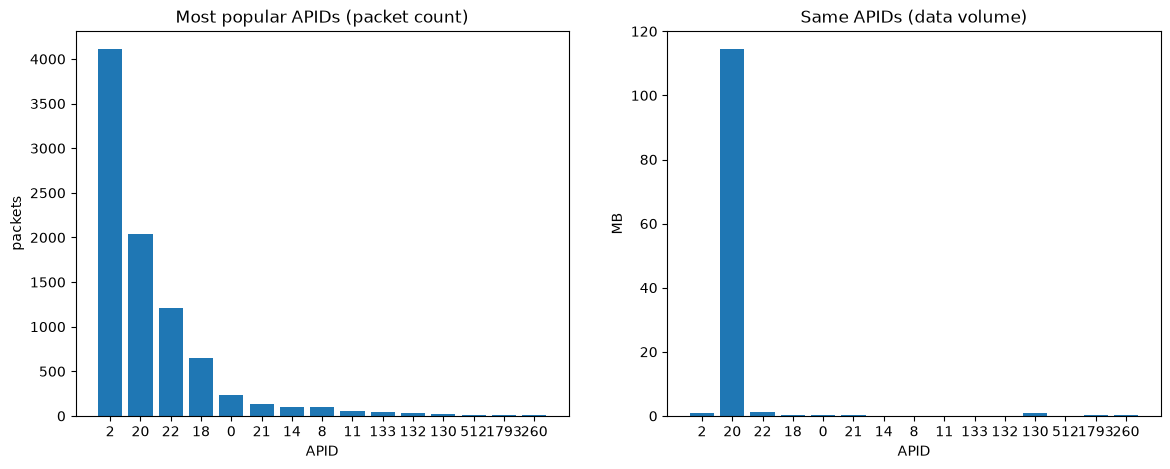

In [4]:
packets: Counter[int] = Counter()
sizes: Counter[int] = Counter()
for path in sorted(CADU_DIR.glob("*.cadu")):
    count_apids(path, packets, sizes)
    print(f"processed {path.name}")

packets.pop(IDLE_APID, None)
top = packets.most_common(TOP_N)
for apid, count in top:
    print(f"APID {apid:4d} (0x{apid:03X}): {count:8d} packets, {sizes[apid] / 1e6:8.2f} MB")

fig, (ax_count, ax_size) = plt.subplots(1, 2, figsize=(14, 5))
labels = [str(apid) for apid, _ in top]
ax_count.bar(labels, [count for _, count in top])
ax_count.set(title="Most popular APIDs (packet count)", xlabel="APID", ylabel="packets")
ax_size.bar(labels, [sizes[apid] / 1e6 for apid, _ in top])
ax_size.set(title="Same APIDs (data volume)", xlabel="APID", ylabel="MB")
plt.show()

In [5]:
# The text segments are records like "F622387446530.1996918 0.000000000 1 ...": an F, a long number, then columns.
TEXT_START = re.compile(rb"F\d{11,}\.\d+ ")
MIN_PRINTABLE = 0.9  # fraction of printable characters needed for a match to count as a text segment


def printable_fraction(data: bytes) -> float:
    return sum(32 <= b < 127 or b in (9, 10, 13) for b in data) / max(len(data), 1)


segments = []  # (file name, vcid, apid, packet sequence count, offset of the text in the packet, text)
for path in sorted(CADU_DIR.glob("*.cadu")):
    for vcid, packet in iter_packets(path):
        match = TEXT_START.search(packet)
        if match is None:
            continue
        text = packet[match.start() :].rstrip(b"\x00")
        if printable_fraction(text) < MIN_PRINTABLE:
            continue
        seq = int.from_bytes(packet[2:4]) & 0x3FFF
        segments.append((path.name, vcid, packet_apid(packet), seq, match.start(), text.decode("ascii", "replace")))

segment_apids = Counter(apid for _, _, apid, _, _, _ in segments)
print("APIDs of the text segments:", segment_apids.most_common())

APIDs of the text segments: [(18, 404), (2047, 1), (661, 1), (1965, 1), (461, 1), (750, 1), (272, 1), (1964, 1), (28, 1), (24, 1), (11, 1), (233, 1), (1574, 1), (62, 1), (1656, 1), (711, 1)]


In [6]:
# A handful of one-off hits come from packets that were reassembled across lost frames (their lengths are absurd),
# the APID that really carries the text dominates.
text_apid, _ = segment_apids.most_common(1)[0]
text_segments = [s for s in segments if s[2] == text_apid]

print(f"APID {text_apid}: {len(text_segments)} segments")
print("packet lengths:", Counter(len(text) + offset for _, _, _, _, offset, text in text_segments).most_common(5))
print("text offsets in packet:", Counter(offset for _, _, _, _, offset, _ in text_segments).most_common(5))
print("virtual channels:", Counter(vcid for _, vcid, _, _, _, _ in text_segments))
print("record types (first two characters):", Counter(text[:2] for *_, text in text_segments).most_common())
print("segments per file:", Counter(name for name, *_ in text_segments))

APID 18: 404 segments
packet lengths: [(73, 218), (626, 185), (53892, 1)]
text offsets in packet: [(24, 394), (26, 10)]
virtual channels: Counter({2: 372, 1: 32})
record types (first two characters): [('F4', 219), ('F6', 185)]
segments per file: Counter({'proba2_dump(10).cadu': 167, 'proba2_dump(6).cadu': 118, 'proba2_dump(2).cadu': 98, 'proba2_dump(9).cadu': 9, 'proba2_dump(3).cadu': 7, 'proba2_dump(4).cadu': 2, 'proba2_dump.cadu': 2, 'proba2_dump(12).cadu': 1})


In [7]:
shown = set()
for name, vcid, apid, seq, _offset, text in text_segments:
    kind = text[:2]
    if kind not in shown:
        shown.add(kind)
        print(f"--- {name} VC{vcid} APID {apid} seq {seq} ({len(text)} chars)")
        print(text, end="\n\n")

Path("apid_text.txt").write_text(
    "".join(f"# {name} VC{vcid} APID {apid} seq {seq}\n{text}\n" for name, vcid, apid, seq, _, text in text_segments)
)

--- proba2_dump(10).cadu VC1 APID 18 seq 4941 (49 chars)
F482379406450.0182379 191701172  510404562.866^�

--- proba2_dump(10).cadu VC1 APID 18 seq 4942 (602 chars)
F622379406450.0000318 0.01164002821         0.00        +0.000    +0.00 30.5 00  7         0.00        +0.000    +0.00 31.4 01  8         0.00        +0.000    +0.00 30.5 00  5         0.00        +0.000    +0.00 31.4 01 14         0.00        +0.000    +0.00 30.5 01 15         0.00        +0.000    +0.00 31.5 01 22         0.00        +0.000    +0.00 33.3 01 18         0.00        +0.000    +0.00 30.5 00 23         0.00        +0.000    +0.00 30.5 01 27         0.00        +0.000    +0.00 30.5 00 30         0.00        +0.000    +0.00 31.9 01 13         0.00        +0.000    +0.00 30.5 01 41�`



193984

In [8]:
# Same way satdump_decode.cpp tells images apart: APID 20 packets of one image share the timestamp in the first
# 6 payload bytes (days since 1958 offset by 18630, then milliseconds). Not every image has its first segment in the
# dumps, so every distinct timestamp counts. Packets with an absurd day count are not image segments.
SWAP_APID = 20
SWAP_TIME_OFFSET_DAYS = 18630
MAX_PLAUSIBLE_DAYS = 1000


def swap_timestamp(packet: bytes) -> int | None:
    days = int.from_bytes(packet[6:8])
    milliseconds = int.from_bytes(packet[8:12])
    if days > MAX_PLAUSIBLE_DAYS:
        return None
    return (SWAP_TIME_OFFSET_DAYS + days) * 86400 + milliseconds // 1000


per_file = {}  # file name -> {"images": set of timestamps, "F4": count, "F6": count}
for path in sorted(CADU_DIR.glob("*.cadu")):
    stats = per_file[path.name] = {"images": set(), "F4": 0, "F6": 0}
    for _, packet in iter_packets(path):
        apid = packet_apid(packet)
        if apid == SWAP_APID:
            if (timestamp := swap_timestamp(packet)) is not None:
                stats["images"].add(timestamp)
        elif apid == text_apid:
            match = TEXT_START.search(packet)
            if match and printable_fraction(packet[match.start() :]) >= MIN_PRINTABLE:
                stats[packet[match.start() : match.start() + 2].decode()] += 1

print(f"{'file':24s} {'images':>6s} {'F4':>5s} {'F6':>5s}")
for name, stats in per_file.items():
    print(f"{name:24s} {len(stats['images']):6d} {stats['F4']:5d} {stats['F6']:5d}")

file                     images    F4    F6
proba2_dump(1).cadu          10     0     0
proba2_dump(10).cadu         42    93    74
proba2_dump(11).cadu         31     0     0
proba2_dump(12).cadu         42     1     0
proba2_dump(2).cadu          11    54    44
proba2_dump(3).cadu          31     3     4
proba2_dump(4).cadu          11     1     1
proba2_dump(5).cadu          18     0     0
proba2_dump(6).cadu          37    63    55
proba2_dump(7).cadu          19     0     0
proba2_dump(8).cadu          40     0     0
proba2_dump(9).cadu          23     4     5
proba2_dump.cadu             31     0     2


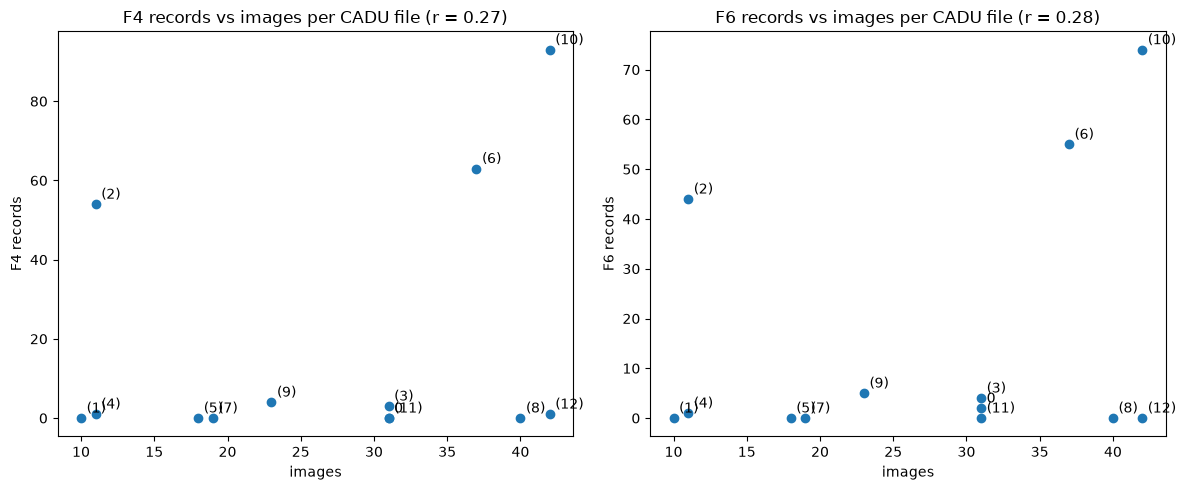

In [ ]:
import numpy as np

names = list(per_file)
images = np.array([len(per_file[name]["images"]) for name in names])
f4 = np.array([per_file[name]["F4"] for name in names])
f6 = np.array([per_file[name]["F6"] for name in names])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, records, label in ((axes[0], f4, "F4 records"), (axes[1], f6, "F6 records")):
    ax.scatter(images, records)
    for name, x, y in zip(names, images, records, strict=True):
        ax.annotate(
            name.removeprefix("proba2_dump").removesuffix(".cadu") or "0",
            (x, y),
            textcoords="offset points",
            xytext=(4, 4),
        )
    ax.set(
        title=f"{label} vs images per CADU file (r = {np.corrcoef(images, records)[0, 1]:.2f})",
        xlabel="images",
        ylabel=label,
    )
fig.tight_layout()
plt.show()